# C — BERT, RoBERTa và DistilBERT của lượt chạy cục bộ
Notebook kiểm bộ 9 checkpoint do `scripts.pipeline.complete_project` tạo trên máy này.
Mỗi kiến trúc có ba seed 42, 123, 2026. Kết quả được đối chiếu với `reports/project_results/`,
không dùng bảng số hoặc checkpoint riêng của báo cáo 2.1 thay cho lượt chạy mới.
Run All đọc hồ sơ, kiểm BCE và suy luận test thật; không huấn luyện lại hoặc tìm ngưỡng bằng test.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root
from src.datasets.goemotions import load_goemotions, multi_hot, sha256, REVISION
from src.evaluation.protocols import read_json
from src.evaluation.metrics import evaluate_multilabel
from src.models.transformer import METRIC_NAMES
ARTIFACTS = artifacts_root()
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_colwidth', 100)
print('Python:', sys.version.split()[0])
print('Dataset revision:', REVISION)
print('Artifacts:', ARTIFACTS.name)

from src.notebook_support import replay_test, benchmark
from src.models.transformer import ARCHITECTURES
verified, frames, labels = benchmark(str(ARTIFACTS))
history = pd.DataFrame([dict(architecture=r['architecture'], seed=r['seed'], selected_epoch=r['selected_epoch'], **e)
                        for r in verified['histories'] for e in r['history']])
print('Đã kiểm 9 checkpoint và 72 dòng của lượt chạy cục bộ.')

Python: 3.12.6
Dataset revision: add492243ff905527e67aeb8b80c082af02207c3
Artifacts: goemotions-multilabel-classification


PASS A: 12 dòng từ scores thật


PASS B: 6 dòng từ scores thật

PASS C: bert seed 42


PASS C: bert seed 123


...

PASS C: roberta seed 2026


PASS C: distilbert seed 42


PASS C: distilbert seed 123


PASS C: distilbert seed 2026


Đã kiểm 9 checkpoint và 72 dòng của lượt chạy cục bộ.


## 1. Cấu hình thật, ba seed và checkpoint đã chọn

In [2]:
configurations = []
for run in verified['histories']:
    configurations.append({**run['config'], 'architecture':run['architecture'], 'seed':run['seed'],
        'selected_epoch':run['selected_epoch'], 'model_revision':run['model_revision']})
display(pd.DataFrame(configurations)[['architecture','seed','learning_rate','epochs',
    'selected_epoch','batch_size','max_length','model_revision']])
print('Demo chọn bằng validation Macro-F1 @0.5:', verified['selection'])
assert len(configurations) == 9

,architecture,seed,learning_rate,epochs,selected_epoch,batch_size,max_length,model_revision
0,bert,42,0.00005,4,4,16,128,cd5ef92a9fb2f889e972770a36d4ed042daf221e
1,bert,123,0.00005,4,4,16,128,cd5ef92a9fb2f889e972770a36d4ed042daf221e
2,bert,2026,0.00005,4,4,16,128,cd5ef92a9fb2f889e972770a36d4ed042daf221e
3,roberta,42,0.00002,3,3,16,128,e2da8e2f811d1448a5b465c236feacd80ffbac7b
4,roberta,123,0.00002,3,3,16,128,e2da8e2f811d1448a5b465c236feacd80ffbac7b
5,roberta,2026,0.00002,3,3,16,128,e2da8e2f811d1448a5b465c236feacd80ffbac7b
6,distilbert,42,0.00002,3,3,16,128,12040accade4e8a0f71eabdb258fecc2e7e948be
7,distilbert,123,0.00002,3,3,16,128,12040accade4e8a0f71eabdb258fecc2e7e948be
8,distilbert,2026,0.00002,3,3,16,128,12040accade4e8a0f71eabdb258fecc2e7e948be


Demo chọn bằng validation Macro-F1 @0.5: {'architecture': 'bert', 'seed': 123}


## 2. Tokenize, head 28 logits và BCE trên batch train thật
    Cell nạp checkpoint seed 42 của mỗi kiến trúc; chỉ forward, không cập nhật weights.
    Kiểm loss model bằng BCEWithLogitsLoss, không dùng softmax/argmax ép một nhãn.

In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from scripts.transformers.train_transformer import encoded_dataset, trim_padding_collate
torch.set_num_threads(4)
loss_checks = []
for architecture in ARCHITECTURES:
    folder = ARTIFACTS/f'data/processed/transformers/{architecture}/seed_42/full/standard/checkpoint'
    tokenizer = AutoTokenizer.from_pretrained(folder, local_files_only=True)
    model = AutoModelForSequenceClassification.from_pretrained(folder, local_files_only=True).eval()
    dataset, _ = encoded_dataset(frames['train'].head(4), tokenizer, labels, 128)
    batch = trim_padding_collate([dataset[j] for j in range(4)])
    with torch.inference_mode():
        out = model(**batch)
        expected = torch.nn.functional.binary_cross_entropy_with_logits(out.logits, batch['labels'])
    torch.testing.assert_close(out.loss, expected)
    loss_checks.append(dict(architecture=architecture, input_shape=str(tuple(batch['input_ids'].shape)),
        target_shape=str(tuple(batch['labels'].shape)), logits_shape=str(tuple(out.logits.shape)),
        bce=float(out.loss), training_update=False))
    del model, dataset, batch, out
display(pd.DataFrame(loss_checks))

D:\Nam_3\HK1\NLP\LT\goemotions-multilabel-classification\.venv-huy\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,architecture,input_shape,target_shape,logits_shape,bce,training_update
0,bert,"(4, 25)","(4, 28)","(4, 28)",0.028296,False
1,roberta,"(4, 24)","(4, 28)","(4, 28)",0.073598,False
2,distilbert,"(4, 24)","(4, 28)","(4, 28)",0.056296,False


## 3. Code huấn luyện dùng chung cho ba kiến trúc
Cell hiển thị code; Run All không gọi huấn luyện. Checkpoint được chọn bằng validation.
Các lượt chạy cục bộ dùng cùng implementation, BCE 28 nhãn và protocol đã khóa.

In [4]:
import inspect
from IPython.display import Code
from scripts.transformers import train_transformer
display(Code(inspect.getsource(train_transformer.main), language='python'))

def main():
    # BƯỚC 1 — Cấu hình và thư mục; resume chỉ bỏ qua run đã hoàn tất đúng hash.
    configure_console()
    args = parse_args()
    config = training_config(args.architecture, smoke=args.smoke, weighted=args.weighted,
                             epochs=args.epochs, learning_rate=args.learning_rate,
                             batch_size=args.batch_size, gradient_accumulation=args.gradient_accumulation,
                             max_length=args.max_length, device=args.device, revision=args.revision)
    output = run_folder(ROOT, args.architecture, args.seed, smoke=args.smoke, weighted=args.weighted)
    metadata_path = output / "run_metadata.json"
    if metadata_path.exists() and args.resume:
        previous = json.loads(metadata_path.read_text(encoding="utf-8"))
        if previous.get("completed"):
            previous = load_transformer_run(output, require_full=not args.smoke, expected_config=config)
            if previous["architecture"] != args.architecture or previous["seed"] != args.seed:
                raise ValueError("Run có seed/kiến trúc khác")
            print(f"Đã hoàn tất, hash/config đúng; bỏ qua {output}", flush=True)
            return
        if not args.overwrite:
            raise RuntimeError("Run này bị ngắt trước khi hoàn tất. Chạy lại đúng seed với "
                               "--overwrite; có thể kết hợp --resume để bỏ qua các seed đã xong.")
    if output.exists() and any(output.iterdir()) and not args.overwrite:
        raise FileExistsError(f"Run đã có dữ liệu: {output}. Dùng --resume hoặc --overwrite.")

    # Imports nặng nằm sau phần argparse/resume: --help không cần GPU/checkpoint.
    import torch
    import transformers
    from huggingface_hub import HfApi
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

    seed_everything(args.seed)
    torch.set_num_threads(4)  # Tránh quá nhiều CPU threads trên Windows 16 GB RAM.
    device = resolve_device(args.device)
    amp_enabled = device.type == "cuda"
    # Khóa cùng SHA cho tokenizer và encoder; không bật remote custom code.
    revision = HfApi().model_info(config["checkpoint"], revision=args.revision).sha
    if not revision:
        raise RuntimeError("Không resolve được commit SHA của checkpoint")
    started = time.perf_counter()
    frames, labels, manifest = load_goemotions(ROOT, write_metadata=False,
                                              splits=("train", "validation"))
    if labels != json.loads((ROOT / "data/labels.json").read_text(encoding="utf-8")):
        raise ValueError("Mapping dữ liệu không khớp data/labels.json")
    train = frames["train"].iloc[:64] if args.smoke else frames["train"]
    validation = frames["validation"].iloc[:32] if args.smoke else frames["validation"]
    if (train["id"].duplicated().any() or validation["id"].duplicated().any() or
            set(train["id"]) & set(validation["id"])):
        raise ValueError("ID trùng trong/between train và validation")
    if any(frame["text"].isna().any() or frame["text"].str.strip().eq("").any()
           for frame in (train, validation)):
        raise ValueError("Train/validation có câu rỗng")
    # BƯỚC 2 — Cùng revision, mapping và độ dài token ở train/validation/inference.
    tokenizer = AutoTokenizer.from_pretrained(config["checkpoint"], revision=revision,
                                               trust_remote_code=False)
    train_data, y_train = encoded_dataset(train, tokenizer, labels, args.max_length)
    validation_data, y_validation = encoded_dataset(validation, tokenizer, labels, args.max_length)
    generator = torch.Generator().manual_seed(args.seed)
    train_loader = torch.utils.data.DataLoader(train_data, batch_size=args.batch_size,
                                               shuffle=True, generator=generator, num_workers=0,
                                               pin_memory=amp_enabled, collate_fn=trim_padding_collate)
    validation_load

## 4. Lịch sử loss và Macro-F1 validation của cả 9 run

,architecture,seed,epoch,train_loss,macro_f1,micro_f1,selected_epoch
0,bert,42,1,0.145031,0.286164,0.529336,4
1,bert,42,2,0.083106,0.424418,0.564804,4
2,bert,42,3,0.064854,0.448077,0.586247,4
3,bert,42,4,0.047407,0.459925,0.578669,4
4,bert,123,1,0.144561,0.301384,0.518215,4
5,bert,123,2,0.084141,0.396706,0.566524,4
6,bert,123,3,0.066099,0.471355,0.579746,4
7,bert,123,4,0.048867,0.480424,0.583046,4
8,bert,2026,1,0.144435,0.296426,0.533570,4
9,bert,2026,2,0.083816,0.415062,0.573298,4


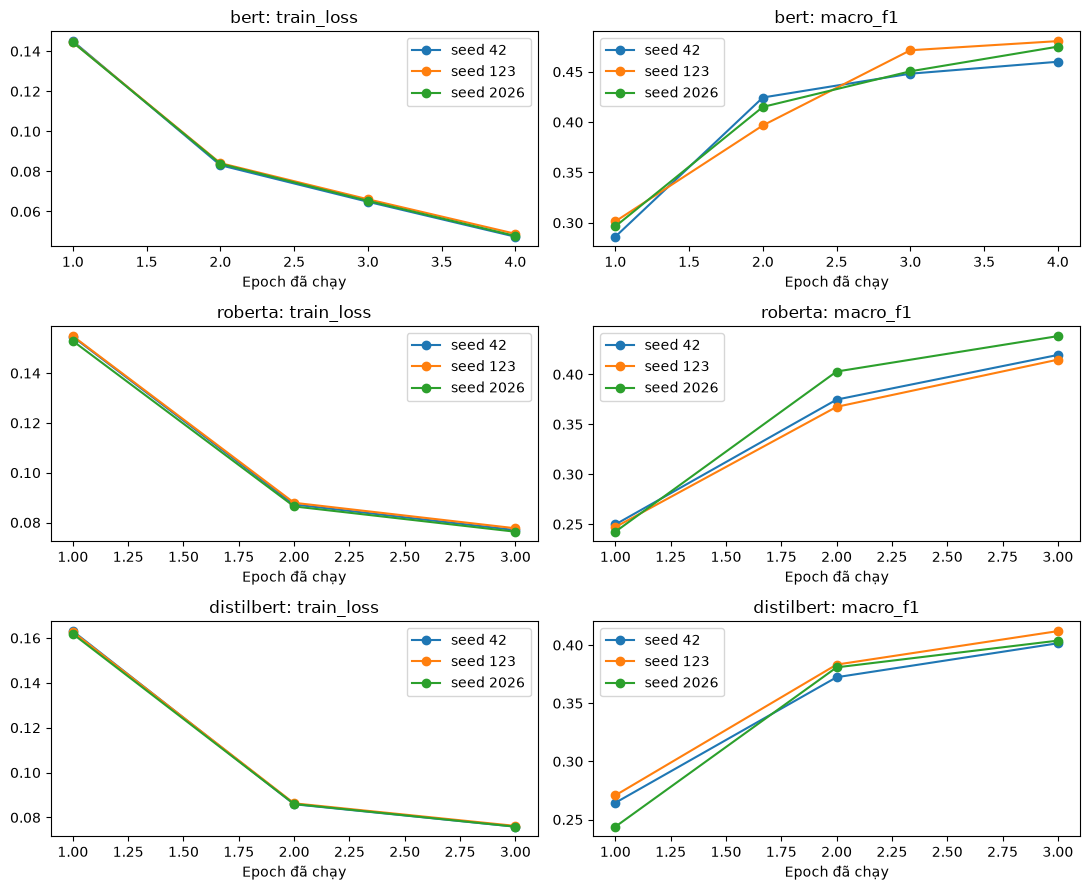

Epoch được chọn ghi riêng theo từng run; chưa có sweep để kết luận siêu tham số tối ưu.


In [5]:
import matplotlib.pyplot as plt
display(history[['architecture','seed','epoch','train_loss','macro_f1','micro_f1','selected_epoch']])
fig, axes = plt.subplots(3, 2, figsize=(11, 9))
for row, architecture in enumerate(ARCHITECTURES):
    for seed, group in history[history.architecture == architecture].groupby('seed'):
        for col, metric in enumerate(('train_loss', 'macro_f1')):
            axes[row,col].plot(group.epoch, group[metric], marker='o', label=f'seed {seed}')
            axes[row,col].set(title=f'{architecture}: {metric}', xlabel='Epoch đã chạy')
            axes[row,col].legend()
plt.tight_layout(); plt.show(); plt.close()
print('Epoch được chọn ghi riêng theo từng run; chưa có sweep để kết luận siêu tham số tối ưu.')

## 5. Validation và lựa chọn mô hình trước test
    Macro-F1 fixed là tiêu chí chọn kiến trúc; tuned-validation dùng chính dữ liệu
    chọn ngưỡng nên không được coi là test độc lập.

In [6]:
historical = pd.DataFrame(verified['records'])
display(historical[(historical.system.str.startswith('C_')) & (historical.split == 'validation')])
averages = pd.DataFrame(verified['averages'])
display(averages[(averages.system.str.startswith('C_')) & (averages.split == 'validation')]
        [['system','threshold_mode','n_runs','macro_f1_mean','macro_f1_std','micro_f1_mean','micro_f1_std']])
fresh_parts = []

,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss
18,C_bert,42.0,validation,fixed,5426,0.459925,0.578669,0.517258,0.423398,0.635019,0.531505,0.032502
19,C_bert,42.0,validation,global,5426,0.490111,0.570866,0.437445,0.594148,0.479970,0.704232,0.044462
20,C_bert,42.0,validation,tuned,5426,0.524171,0.595144,0.521060,0.549333,0.541346,0.660815,0.037755
24,C_bert,123.0,validation,fixed,5426,0.480424,0.583046,0.573592,0.433359,0.647284,0.530408,0.031857
25,C_bert,123.0,validation,global,5426,0.499514,0.583350,0.471976,0.567587,0.515582,0.671630,0.040289
26,C_bert,123.0,validation,tuned,5426,0.530648,0.604263,0.549709,0.546329,0.546689,0.675392,0.037149
30,C_bert,2026.0,validation,fixed,5426,0.474930,0.575812,0.561974,0.428807,0.635332,0.526489,0.032575
31,C_bert,2026.0,validation,global,5426,0.498194,0.585490,0.496315,0.515417,0.559943,0.613480,0.036478
32,C_bert,2026.0,validation,tuned,5426,0.531530,0.591031,0.538544,0.552940,0.535814,0.658934,0.038294
36,C_roberta,42.0,validation,fixed,5426,0.419459,0.574954,0.580673,0.365675,0.704318,0.485737,0.030159


,system,threshold_mode,n_runs,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std
18,C_bert,fixed,3,0.471760,0.010611,0.579176,0.003644
19,C_bert,global,3,0.495940,0.005091,0.579902,0.007898
20,C_bert,tuned,3,0.528783,0.004018,0.596813,0.006772
24,C_roberta,fixed,3,0.424161,0.012463,0.577900,0.004133
25,C_roberta,global,3,0.480805,0.005735,0.607284,0.006283
26,C_roberta,tuned,3,0.503668,0.007958,0.609741,0.004751
30,C_distilbert,fixed,3,0.405782,0.005498,0.573810,0.004381
31,C_distilbert,global,3,0.475658,0.003042,0.592041,0.009230
32,C_distilbert,tuned,3,0.510483,0.003683,0.604067,0.002948


## Suy luận test mới — bert, đủ ba seed
        Mỗi checkpoint chạy thực sự trên 5.427 câu; áp fixed/global/tuned đã khóa.
        Cell sẽ dừng nếu metric mới lệch bộ số báo cáo quá 1e-12.

In [7]:
part = pd.concat([replay_test(ARTIFACTS, 'C_bert', seed)
                  for seed in (42, 123, 2026)], ignore_index=True)
fresh_parts.append(part)
display(part)
print('PASS bert: 3 checkpoint, 9 dòng test; sai lệch scores lớn nhất:', part.score_max_abs_diff.max())

,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss,metric_max_abs_diff,score_max_abs_diff
0,C_bert,42,test,fixed,5427,0.468295,0.584901,0.533099,0.429792,0.640760,0.538000,0.031805,0.0,0.0
1,C_bert,42,test,global,5427,0.479144,0.568130,0.447721,0.585458,0.474616,0.707537,0.044802,0.0,0.0
2,C_bert,42,test,tuned,5427,0.506072,0.584961,0.510906,0.532979,0.526769,0.657608,0.038867,0.0,0.0
3,C_bert,123,test,fixed,5427,0.474661,0.582492,0.554710,0.433558,0.641284,0.533576,0.031858,0.0,0.0
4,C_bert,123,test,global,5427,0.485639,0.574772,0.445108,0.556929,0.504720,0.667404,0.041130,0.0,0.0
5,C_bert,123,test,tuned,5427,0.504186,0.586798,0.511272,0.524005,0.528125,0.660136,0.038722,0.0,0.0
6,C_bert,2026,test,fixed,5427,0.477314,0.585412,0.577527,0.433029,0.647939,0.533892,0.031496,0.0,0.0
7,C_bert,2026,test,global,5427,0.493443,0.591053,0.496153,0.511303,0.566401,0.617949,0.035616,0.0,0.0
8,C_bert,2026,test,tuned,5427,0.505855,0.585517,0.514505,0.540009,0.528283,0.656660,0.038722,0.0,0.0


PASS bert: 3 checkpoint, 9 dòng test; sai lệch scores lớn nhất: 0.0


## Suy luận test mới — roberta, đủ ba seed
        Mỗi checkpoint chạy thực sự trên 5.427 câu; áp fixed/global/tuned đã khóa.
        Cell sẽ dừng nếu metric mới lệch bộ số báo cáo quá 1e-12.

In [8]:
part = pd.concat([replay_test(ARTIFACTS, 'C_roberta', seed)
                  for seed in (42, 123, 2026)], ignore_index=True)
fresh_parts.append(part)
display(part)
print('PASS roberta: 3 checkpoint, 9 dòng test; sai lệch scores lớn nhất:', part.score_max_abs_diff.max())

,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss,metric_max_abs_diff,score_max_abs_diff
0,C_roberta,42,test,fixed,5427,0.416596,0.574928,0.573653,0.368950,0.703984,0.485859,0.029923,0.0,0.0
1,C_roberta,42,test,global,5427,0.470930,0.610701,0.458988,0.509996,0.562992,0.667246,0.035431,0.0,0.0
2,C_roberta,42,test,tuned,5427,0.478786,0.605277,0.482198,0.507689,0.560431,0.657924,0.035741,0.0,0.0
3,C_roberta,123,test,fixed,5427,0.417224,0.576767,0.573839,0.368564,0.716026,0.482857,0.029515,0.0,0.0
4,C_roberta,123,test,global,5427,0.468748,0.606581,0.486868,0.504039,0.562441,0.658240,0.035563,0.0,0.0
5,C_roberta,123,test,tuned,5427,0.474445,0.593540,0.456378,0.524399,0.532288,0.670722,0.038261,0.0,0.0
6,C_roberta,2026,test,fixed,5427,0.435484,0.582295,0.575616,0.385530,0.707571,0.494707,0.029561,0.0,0.0
7,C_roberta,2026,test,global,5427,0.472767,0.596845,0.435831,0.546387,0.518912,0.702323,0.039518,0.0,0.0
8,C_roberta,2026,test,tuned,5427,0.491093,0.601325,0.489096,0.523742,0.552468,0.659662,0.036432,0.0,0.0


PASS roberta: 3 checkpoint, 9 dòng test; sai lệch scores lớn nhất: 0.0


## Suy luận test mới — distilbert, đủ ba seed
        Mỗi checkpoint chạy thực sự trên 5.427 câu; áp fixed/global/tuned đã khóa.
        Cell sẽ dừng nếu metric mới lệch bộ số báo cáo quá 1e-12.

In [9]:
part = pd.concat([replay_test(ARTIFACTS, 'C_distilbert', seed)
                  for seed in (42, 123, 2026)], ignore_index=True)
fresh_parts.append(part)
display(part)
print('PASS DistilBERT: 3 checkpoint, 9 dòng test; sai lệch scores lớn nhất:', part.score_max_abs_diff.max())

,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss,metric_max_abs_diff,score_max_abs_diff
0,C_distilbert,42,test,fixed,5427,0.416795,0.573216,0.591906,0.356420,0.716248,0.477801,0.029634,0.0,0.0
1,C_distilbert,42,test,global,5427,0.466461,0.596857,0.473013,0.522312,0.524140,0.693000,0.038992,0.0,0.0
2,C_distilbert,42,test,tuned,5427,0.488476,0.595143,0.489470,0.521679,0.540426,0.662190,0.037524,0.0,0.0
3,C_distilbert,123,test,fixed,5427,0.417538,0.578097,0.602040,0.358091,0.719088,0.483331,0.029384,0.0,0.0
4,C_distilbert,123,test,global,5427,0.463453,0.577519,0.442992,0.561153,0.477811,0.729815,0.044473,0.0,0.0
5,C_distilbert,123,test,tuned,5427,0.482743,0.599699,0.508358,0.499119,0.549290,0.660294,0.036715,0.0,0.0
6,C_distilbert,2026,test,fixed,5427,0.411726,0.576370,0.599664,0.354425,0.711369,0.484437,0.029660,0.0,0.0
7,C_distilbert,2026,test,global,5427,0.462751,0.597598,0.438820,0.519872,0.526012,0.691736,0.038801,0.0,0.0
8,C_distilbert,2026,test,tuned,5427,0.500938,0.597241,0.511025,0.522202,0.550013,0.653342,0.036701,0.0,0.0


PASS DistilBERT: 3 checkpoint, 9 dòng test; sai lệch scores lớn nhất: 0.0


## 6. Tổng hợp test mean ± sample std từ kết quả suy luận mới

In [10]:
from scripts.analysis.summarize_project import summarize
fresh = pd.concat(fresh_parts, ignore_index=True)
assert len(fresh) == 27 and (fresh.n_samples == 5427).all()
fresh_averages = summarize(fresh.to_dict('records'))
for row in fresh_averages:
    old = next(r for r in verified['averages'] if all(r[k] == row[k]
                for k in ('system','split','threshold_mode')))
    for metric in METRIC_NAMES:
        for suffix in ('_mean','_std'):
            assert abs(row[metric+suffix]-old[metric+suffix]) <= 1e-12
display(pd.DataFrame(fresh_averages)[['system','threshold_mode','n_runs',
    'macro_f1_mean','macro_f1_std','micro_f1_mean','micro_f1_std','hamming_loss_mean']])
print('PASS: 27 dòng test và 9 nhóm mean/std tính mới khớp báo cáo.')

,system,threshold_mode,n_runs,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,hamming_loss_mean
0,C_bert,fixed,3,0.473424,0.004635,0.584269,0.001559,0.031720
1,C_bert,global,3,0.486075,0.007160,0.577985,0.011795,0.040516
2,C_bert,tuned,3,0.505371,0.001032,0.585759,0.000942,0.038770
3,C_roberta,fixed,3,0.423101,0.010728,0.577997,0.003835,0.029666
4,C_roberta,global,3,0.470815,0.002012,0.604709,0.007116,0.036837
5,C_roberta,tuned,3,0.481441,0.008636,0.600047,0.005972,0.036811
6,C_distilbert,fixed,3,0.415353,0.003163,0.575894,0.002475,0.029559
7,C_distilbert,global,3,0.464222,0.001971,0.590658,0.011384,0.040755
8,C_distilbert,tuned,3,0.490719,0.009303,0.597361,0.002280,0.036980


PASS: 27 dòng test và 9 nhóm mean/std tính mới khớp báo cáo.


## 7. Ví dụ dự đoán cùng ID từ scores vừa suy luận
    Ba mô hình dùng seed 123 và cùng câu test để đối chiếu. Mẫu lấy theo thứ tự dữ liệu,
    không sửa văn bản hay chọn lại ngưỡng theo kết quả test.

In [11]:
from src.models.baseline import load_aligned_scores
examples = []
test = frames['test']
for architecture in ARCHITECTURES:
    scores = load_aligned_scores(ROOT/f'reports/notebook_replay/C_{architecture}_123_test.npz', test.id.tolist(), labels)
    protocol_path = ARTIFACTS/f'data/processed/transformers/{architecture}/seed_123/full/standard/final_protocol.json'
    protocol = read_json(protocol_path)
    thresholds = next(c['thresholds'] for c in protocol['configurations'] if c['threshold_mode']=='tuned')
    for i in range(3):
        examples.append(dict(architecture=architecture, id=test.id.iloc[i], text=test.text.iloc[i],
            truth=[labels[j] for j in test.labels.iloc[i]],
            predicted=[labels[j] for j in np.flatnonzero(scores[i] >= thresholds)]))
display(pd.DataFrame(examples))

,architecture,id,text,truth,predicted
0,bert,eecwqtt,"I’m really sorry about your situation :( Although I love the names Sapphira, Cirilla, and Scarlett!",[sadness],"[love, remorse, sadness]"
1,bert,ed5f85d,It's wonderful because it's awful. At not with.,[admiration],"[admiration, disgust]"
2,bert,een27c3,"Kings fan here, good luck to you guys! Will be an interesting game to watch!",[excitement],[optimism]
3,roberta,eecwqtt,"I’m really sorry about your situation :( Although I love the names Sapphira, Cirilla, and Scarlett!",[sadness],"[remorse, sadness]"
4,roberta,ed5f85d,It's wonderful because it's awful. At not with.,[admiration],"[admiration, disgust]"
5,roberta,een27c3,"Kings fan here, good luck to you guys! Will be an interesting game to watch!",[excitement],[optimism]
6,distilbert,eecwqtt,"I’m really sorry about your situation :( Although I love the names Sapphira, Cirilla, and Scarlett!",[sadness],"[remorse, sadness]"
7,distilbert,ed5f85d,It's wonderful because it's awful. At not with.,[admiration],"[admiration, disgust]"
8,distilbert,een27c3,"Kings fan here, good luck to you guys! Will be an interesting game to watch!",[excitement],"[admiration, optimism]"


## 8. Phạm vi kiểm chứng
Kiểm đủ 9 checkpoint của pipeline cục bộ, suy luận lại test và so metric với bảng mới.
Thời điểm huấn luyện và seed nằm trong metadata; thời điểm chạy notebook được ghi riêng.
Mô hình demo được chọn theo validation của lượt chạy này, không cố định kiến trúc thắng.

In [12]:
display(pd.Series({'full_checkpoints_replayed': int(fresh.groupby(['system','seed']).ngroups),
    'test_rows_recomputed': len(fresh), 'test_groups_recomputed': len(fresh_averages),
    'max_score_difference': fresh.score_max_abs_diff.max(),
    'max_metric_difference': fresh.metric_max_abs_diff.max(), 'training_repeated': False}))

full_checkpoints_replayed        9
test_rows_recomputed            27
test_groups_recomputed           9
max_score_difference           0.0
max_metric_difference          0.0
training_repeated            False
dtype: object